---
title: "Practice Activity 9-1: Regression Models and Pipelines"
author: "Shiqi Wu"
format:
  html:
    embed-resources: true
    code-overflow: wrap
---

# K-Nearest Neighbors and Decision Trees for Regression

Before we implement models using scikit-learn, let's think conceptually about the $k$-nearest neighbors and decision tree algorithms for regression.

In [1]:
import pandas as pd

import numpy as np

import matplotlib.pyplot as plt

## Visualizing K-Nearest Neighbors Regression Functions

A predictive model is simply a function $f$ that maps feature values ${\bf x}$ to target values $y$. We can visualize $f$ when ${\bf x}$ consists of just a single feature. We have seen that a linear regression function $f$ based on a single feature $x$ is a linear function of $x$. What does $f$ look like when the model is a $k$-nearest neighbors regressor?


### K-Nearest Neighbors Regression Functions for a Single Quantitative Feature: Wine Data


Recall the wines data set where our target is log(price), a proxy for quality.
We'll use a K-Nearest Neighbors model for predicting log(price) from a single feature, age.

First, we extract the training data. There is no need to scale the features in this case because there is only one feature. (The point of scaling is to bring all of the *feature* variables to the same scale before computing distances between observations.)

In [2]:
bordeaux_df = pd.read_csv("https://dlsun.github.io/pods/data/bordeaux.csv",
                          index_col="year")

# Split the data into training and test sets
bordeaux_train = bordeaux_df.loc[:1980].copy()
bordeaux_test = bordeaux_df.loc[1981:].copy()

# Log transform the target
bordeaux_train["log(price)"] = np.log(bordeaux_train["price"])

# train on a single feature, age
X_train = bordeaux_train[["age"]]
y_train = bordeaux_train["log(price)"]

In [3]:
bordeaux_train[["age", "log(price)"]].sort_values("age").head(5)

,age,log(price)
year,,
1980,12,2.639057
1979,13,3.044522
1978,14,3.295837
1977,15,2.397895
1976,16,3.218876


Let's make a scatterplot of the training data. Careful! In the reading, we made several scatterplots where both the x-axis and y-axis corresponded to *feature* variables (and the target corresponded to color). But now the x-axis is the feature and the y-axis is the target.

<Axes: xlabel='age', ylabel='log(price)'>

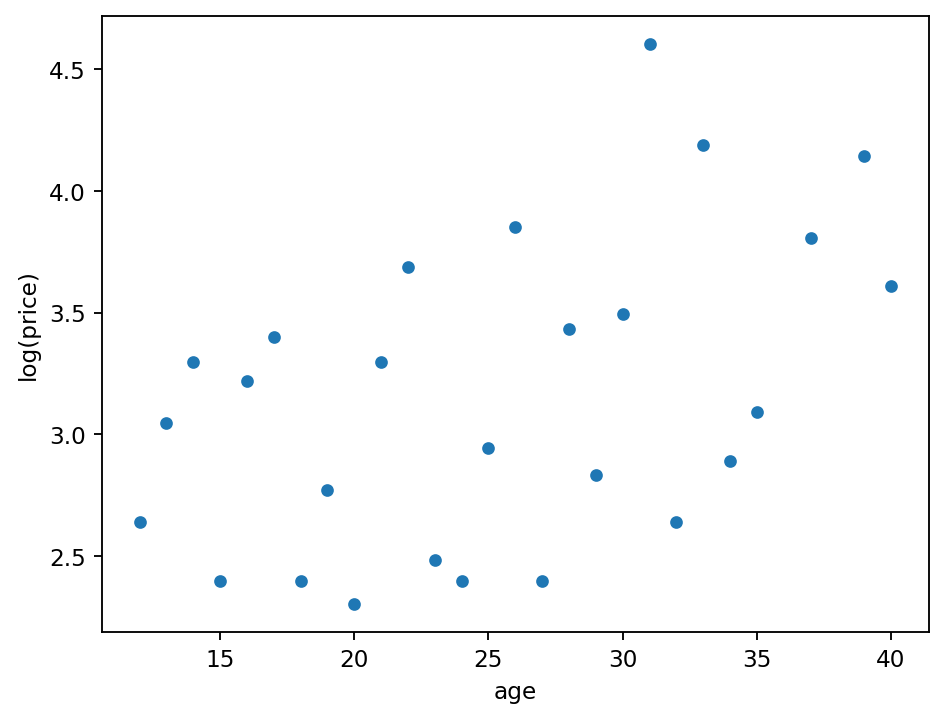

In [4]:
bordeaux_train.plot.scatter(x="age", y="log(price)")

1. Consider a **1-nearest neighbor** regression model. Say we want to add the regression function to the scatterplot. Sketch a plot of what the regression function would look like. **Discuss with your partner before proceeding.** Hint: The smallest ages in the training data are 12, 13, 14, etc. What would the predicted price be for age = 12? age = 13? age = 11.5? age = 12.49? age = 12.51? age = 13.49? age = 13.51?

Answer: The 1-nearest neighbor model predicts log(price) using the training wine with the closest age. The regression function is step-shaped. The prediction stays constant while the same training wine is the nearest neighbor. When the nearest neighbor changes at the midpoint between neighboring training ages, the prediction can jump to a different value.

2. Consider a **2-nearest neighbor** regression model. Say we want to add the regression function to the scatterplot. Sketch a plot of what the regression function would look like. **Discuss with your partner before proceeding.** Hint: The smallest ages in the training data are 12, 13, 14, etc. What would the predicted price be for age = 12? age = 12.99? age = 13.01? age = 13.99? age = 14.01?

Answer: The 2-nearest neighbor model predicts log(price) by averaging the log(price) values of the two training wines with the closest ages. The regression function is still step-shaped. The prediction stays constant while the same two wines are the nearest neighbors. For example, age 12.99 uses the wines with ages 12 and 13, while age 13.01 uses the wines with ages 13 and 14.

3. What would the 27-nearest neighbors regression function look like? **Discuss with your partner before proceeding.** Hint: what is special about 27 in this example?

Answer: The 27-nearest neighbors regression function is a horizontal line. There are 27 wines in the training data, so the model uses all training wines for every prediction. The predicted log(price) is the mean log(price) of all 27 training wines, regardless of age.

4. Now we'll fit a K-nearest neighbors regression model and plot the regression function for K=1, 2, 10, 27. The code below basically implements the code from the previous part for each of the values of K. Run the code and **discuss the output with your partner**. Do the regression functions look like what you expected? What happens as K increases?

<Axes: xlabel='age', ylabel='log(price)'>

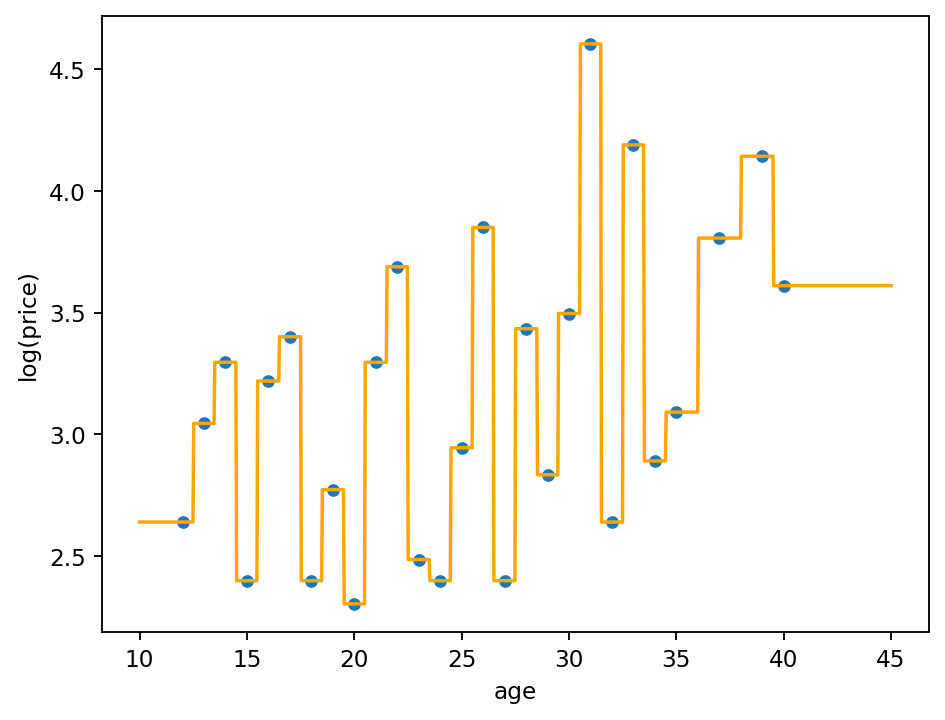

In [5]:
# 1-nearest neighbor model
from sklearn.neighbors import KNeighborsRegressor

# Fit k-nearest neighbors
model = KNeighborsRegressor(n_neighbors=1)
model.fit(X=X_train, y=y_train)

# Define a grid of feature values to make predictions for
X_new = pd.DataFrame()
X_new["age"] = np.linspace(10, 45, num=1000)

# Make predictions at those feature values.
y_new_ = pd.Series(
    # ADD YOUR CODE HERE,
    model.predict(X_new),
    index=X_new["age"]
)

# Plot the scatter plot and the predictions (regression function)
bordeaux_train.plot.scatter(x="age", y="log(price)")
y_new_.plot.line(color = "orange")


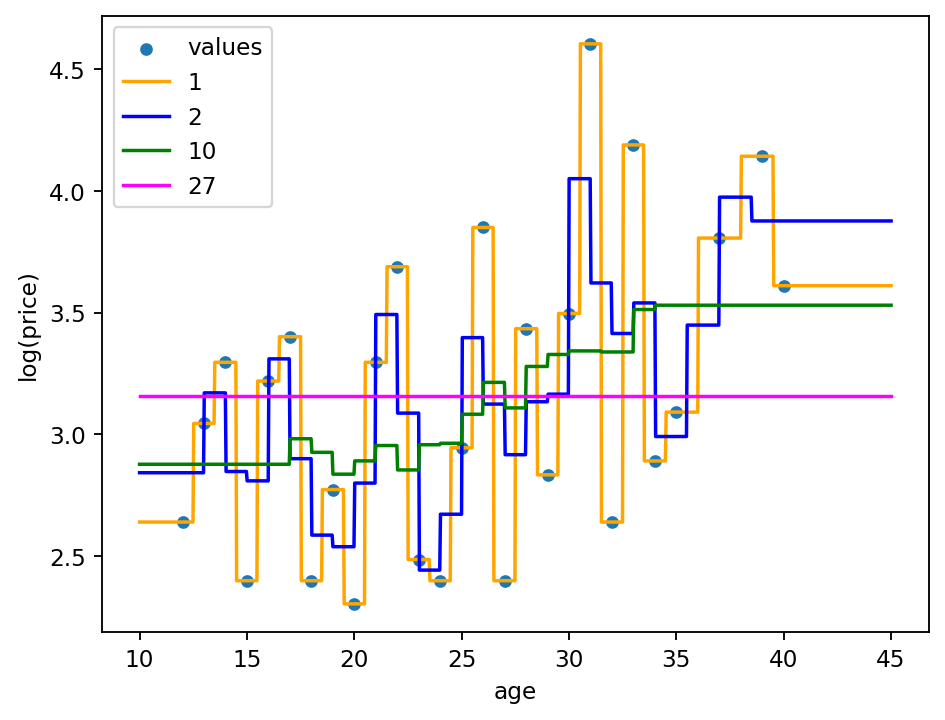

In [6]:
# k-nearest neighbors for several values of k
ks = [1, 2, 10, 27]
colors = ["orange", "blue", "green", "magenta", "black"]

bordeaux_train.plot.scatter(x="age", y="log(price)")

# Define a grid of feature values.
X_new = pd.DataFrame()
X_new["age"] = np.linspace(10, 45, num=1000)

for i in range(len(ks)):

  # Fit k-nearest neighbors
  model = KNeighborsRegressor(n_neighbors=ks[i])
  model.fit(X=X_train, y=y_train)

  # Make predictions at those feature values.
  y_new_ = pd.Series(
      model.predict(X_new),
      index=X_new["age"]
  )

  # Plot the predictions.
  y_new_.plot.line(color = colors[i])
  plt.legend(["values"] + ks);


Answer: The plots match the expected shapes. The K = 1 model is step-shaped and follows the training values closely. As K increases, the predictions become less variable because the model averages more neighbors. The K = 2 and K = 10 models are still step-shaped, but their fluctuations are smaller overall. The K = 27 model is a horizontal line at the mean log(price) of all 27 training wines.

### K-Nearest Neighbors Regression Functions for a Single Categorical Feature: Housing Data

Recall the Ames housing data set. We'll use a single categorical feature---Neighborhood---to predict SalePrice.

In [7]:
df_ames = pd.read_csv("http://dlsun.github.io/pods/data/AmesHousing.txt", sep = "\t")

df_ames[["Neighborhood", "SalePrice"]]

,Neighborhood,SalePrice
0,NAmes,215000
1,NAmes,105000
2,NAmes,172000
3,NAmes,244000
4,Gilbert,189900
...,...,...
2925,Mitchel,142500
2926,Mitchel,131000
2927,Mitchel,132000
2928,Mitchel,170000


We'll fit a **10-nearest neighbors** regression model to predict house price using **Neighborhood** as the only feature. Since Neighborhood is categorical we first need to convert it to dummies, using a `ColumnTransformer` and a `Pipeline`.

In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

X = df_ames[["Neighborhood"]]
y = df_ames["SalePrice"]

ct = ColumnTransformer(
    [("dummify", OneHotEncoder(), ["Neighborhood"])]
)

knn_model = Pipeline([
    ("preprocessing", ct),
    ("knn", KNeighborsRegressor(n_neighbors=10))
])

knn_model.fit(X, y)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessing', ...), ('knn', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('dummify', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains spar

Now we'll find the predicted price for each Neighborhood.

In [9]:
neighborhoods = pd.Series(df_ames["Neighborhood"].unique(), name="Neighborhood").to_frame()
neighborhoods["predicted"] = knn_model.predict(neighborhoods)
neighborhoods

,Neighborhood,predicted
0,NAmes,142771.0
1,Gilbert,221722.5
2,StoneBr,300637.0
3,NWAmes,180795.0
4,Somerst,230960.0
5,BrDale,108850.0
6,NPkVill,140115.0
7,NridgHt,346588.3
8,Blmngtn,209917.9
9,NoRidge,325105.0


Let's compare the predicted prices to the mean price for each neighborhood.

In [10]:
pd.merge(pd.merge(neighborhoods,
                  df_ames.groupby("Neighborhood")["SalePrice"].mean(), left_on = "Neighborhood", right_index = True),
         df_ames["Neighborhood"].value_counts(), left_on = "Neighborhood", right_index = True).sort_values("count")

,Neighborhood,predicted,SalePrice,count
27,Landmrk,122920.0,137000.000000,1
26,GrnHill,150790.0,280000.000000,2
12,Greens,181175.0,193531.250000,8
21,Blueste,143590.0,143590.000000,10
6,NPkVill,140115.0,140710.869565,23
25,Veenker,254750.0,248314.583333,24
8,Blmngtn,209917.9,196661.678571,28
5,BrDale,108850.0,105608.333333,30
24,MeadowV,104390.0,95756.486486,37
16,ClearCr,222100.0,208662.090909,44


 5. For what neighborhood is the predicted price equal to the neighborhood's mean price? Why? What is special about that neighborhood? Can you explain why the predicted prices don't match the mean price for the other neighborhoods?

Answer: Blueste has a predicted price equal to its mean sale price, both 143590 dollars. It has exactly 10 houses, so the 10-nearest neighbors model uses all houses in that neighborhood. For neighborhoods with fewer than 10 houses, the model includes houses from other neighborhoods to reach 10 neighbors. For neighborhoods with more than 10 houses, it uses only 10 houses from that neighborhood, not all of them. Therefore, the predicted prices do not necessarily equal the neighborhood means.

### K-Nearest Neighbors Regression Functions for Two Quantitative Features: Sketching for Small Training Data

When there are multiple features, a regression function will be a surface in a higher dimensional space and is therefore difficult to visualize. Essentially the regression function splits the feature space into regions based on which $K$ points in the training data are closest, and makes constant predictions over these regions so that the regression surface has something like a ["log step"](https://i.pinimg.com/originals/f3/61/21/f36121c84fa42b6cad525f865d61d049.png) shape.

We'll sketch plots of the regression surface when there are two quantitative features and the training data only contains a few observations. Assume that the features have already been scaled and that Euclidean distance is used to determine nearest neighbors.

6. Consider **1-nearest neighbors** regression model based on two quantitative features which have already been scaled. Imagine the training data set only contains 2 observations. Skecth a plot of the regression function.  **Discuss with your partner.**

Answer: The 1-nearest neighbor regression function divides the feature space into two regions, separated by the perpendicular bisector of the line connecting the two training points. In each region, the prediction equals the target value of the closer training point. The regression surface consists of two flat regions, with a jump at the boundary if the two target values are different.

7. Consider **1-nearest neighbors** regression model based on two quantitative features which have already been scaled. Imagine the training data set only contains 3 observations. Skecth a plot of the regression function.  **Discuss with your partner.**

Answer: The 1-nearest neighbor regression function divides the feature space into three regions, one for each training point. Within each region, the prediction equals the target value of the closest training point. The boundaries occur where the nearest training points are equally distant. The regression surface is flat within each region and can jump between regions with different target values.

8. Consider **2-nearest neighbors** regression model based on two quantitative features which have already been scaled. Imagine the training data set only contains 3 observations. Skecth a plot of the regression function.  **Discuss with your partner.**

Answer: The 2-nearest neighbors regression function divides the feature space into regions based on the two closest training points. The possible neighbor pairs are A and B, A and C, and B and C. Within each region, the prediction is the mean of the target values of the same two neighbors. The regression surface is flat within each region and can jump when the neighbor pair changes.

## Decision Trees

Back to the wine data. Suppose again that we want to predict log(price) based on just a single feature, age.

<Axes: xlabel='age', ylabel='log(price)'>

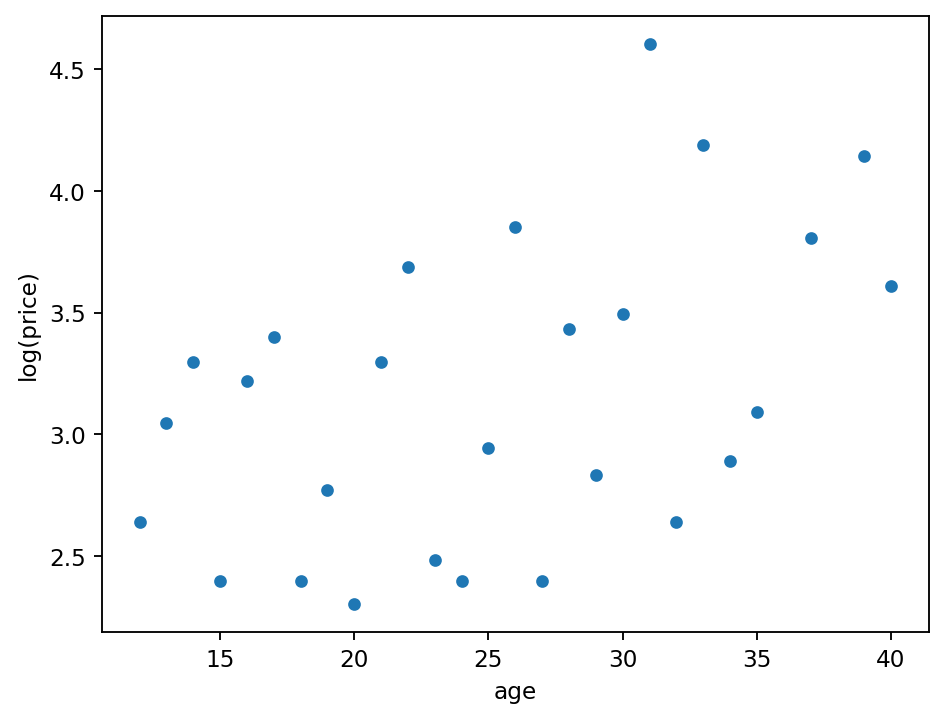

In [11]:
bordeaux_train.plot.scatter(x="age", y="log(price)")

9. Suppose we use a regression decision tree with a single split at 20.5. Sketch a plot of what the regression function would look like.

Answer: The regression function consists of two horizontal segments separated at age 20.5. For ages less than or equal to 20.5, the prediction is the mean log(price) of the training wines in that group. For ages greater than 20.5, the prediction is the mean log(price) of the training wines in the other group. The function jumps at 20.5 if the two group means differ.

10. Suppose we use a decision tree with two splits at 20.5 and 30.5. Sketch a plot of what the regression function would look like.

Answer: The regression function consists of three horizontal segments, with boundaries at ages 20.5 and 30.5. The regions are age less than or equal to 20.5, age greater than 20.5 and less than or equal to 30.5, and age greater than 30.5. In each region, the prediction is the mean log(price) of the training wines in that region. The function can jump at each boundary if the neighboring region means differ.

## Fitting KNN Regression Models with scikit-learn: Housing data

11. Fit a 10-nearest neighbors regression model that predicts the price (just **SalePrice**, not log) of a home using square footage (**Gr Liv Area**), number of bedrooms (**Bedroom AbvGr**), number of full bathrooms (**Full Bath**), number of half bathrooms (**Half Bath**), and **Neighborhood**. Use a pipeline and column transformers as needed. Make a scatter plot of predicting price versus actual price.

In [12]:
numeric_features = [
    "Gr Liv Area",
    "Bedroom AbvGr",
    "Full Bath",
    "Half Bath"
]

categorical_features = ["Neighborhood"]

X = df_ames[numeric_features + categorical_features]
y = df_ames["SalePrice"]

X.head()

,Gr Liv Area,Bedroom AbvGr,Full Bath,Half Bath,Neighborhood
0,1656,3,1,0,NAmes
1,896,2,1,0,NAmes
2,1329,3,1,1,NAmes
3,2110,3,2,1,NAmes
4,1629,3,2,1,Gilbert


In [13]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsRegressor

ct = ColumnTransformer([
    ("standardize", StandardScaler(), numeric_features),
    ("dummify", OneHotEncoder(), categorical_features)
])

knn_model = Pipeline([
    ("preprocessing", ct),
    ("knn", KNeighborsRegressor(n_neighbors=10))
])

knn_model.fit(X, y)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessing', ...), ('knn', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('standardize', ...), ('dummify', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different tran

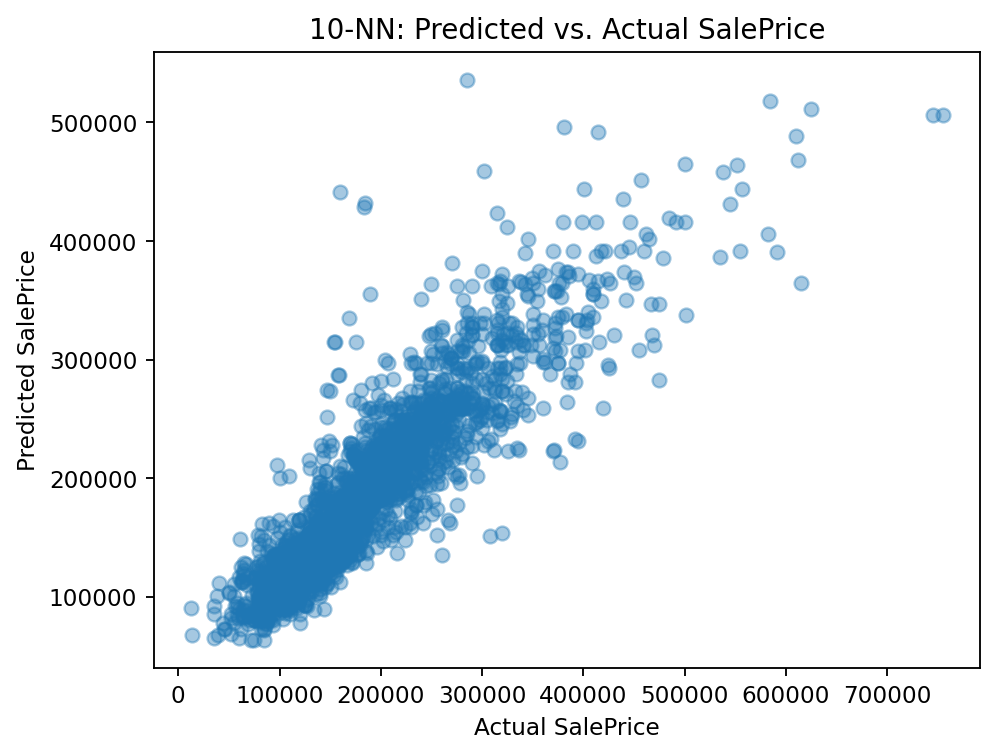

In [14]:
y_pred = knn_model.predict(X)

plt.scatter(y, y_pred, alpha=0.4)
plt.xlabel("Actual SalePrice")
plt.ylabel("Predicted SalePrice")
plt.title("10-NN: Predicted vs. Actual SalePrice")
plt.show()

12. Repeat the previous part to fit a $k$-nearest neighbors model for some other value of $k$. Experiment with different values of $k$. (For this, you can just pick and choose a few, no need to automate it. We'll see how to do that later.) What value of $k$ seems to be "best"? How are you deciding?

In [15]:
from sklearn.model_selection import train_test_split

X_train_housing, X_valid_housing, y_train_housing, y_valid_housing = (
    train_test_split(
        X, y,
        test_size=0.2,
        random_state=42
    )
)

print("Training rows:", len(X_train_housing))
print("Validation rows:", len(X_valid_housing))

Training rows: 2344
Validation rows: 586


In [16]:
from sklearn.metrics import mean_absolute_error

k = 5

ct_housing = ColumnTransformer([
    ("standardize", StandardScaler(), numeric_features),
    ("dummify", OneHotEncoder(handle_unknown="ignore"),
     categorical_features)
])

knn_valid_model = Pipeline([
    ("preprocessing", ct_housing),
    ("knn", KNeighborsRegressor(n_neighbors=k))
])

knn_valid_model.fit(X_train_housing, y_train_housing)

y_valid_pred = knn_valid_model.predict(X_valid_housing)

mae = mean_absolute_error(y_valid_housing, y_valid_pred)

print("K:", k)
print("Validation MAE:", mae)

K: 5
Validation MAE: 26402.254266211603


In [17]:
from sklearn.metrics import mean_absolute_error

k = 10

ct_housing = ColumnTransformer([
    ("standardize", StandardScaler(), numeric_features),
    ("dummify", OneHotEncoder(handle_unknown="ignore"),
     categorical_features)
])

knn_valid_model = Pipeline([
    ("preprocessing", ct_housing),
    ("knn", KNeighborsRegressor(n_neighbors=k))
])

knn_valid_model.fit(X_train_housing, y_train_housing)

y_valid_pred = knn_valid_model.predict(X_valid_housing)

mae = mean_absolute_error(y_valid_housing, y_valid_pred)

print("K:", k)
print("Validation MAE:", mae)

K: 10
Validation MAE: 26394.38566552901


In [18]:
from sklearn.metrics import mean_absolute_error

k = 20

ct_housing = ColumnTransformer([
    ("standardize", StandardScaler(), numeric_features),
    ("dummify", OneHotEncoder(handle_unknown="ignore"),
     categorical_features)
])

knn_valid_model = Pipeline([
    ("preprocessing", ct_housing),
    ("knn", KNeighborsRegressor(n_neighbors=k))
])

knn_valid_model.fit(X_train_housing, y_train_housing)

y_valid_pred = knn_valid_model.predict(X_valid_housing)

mae = mean_absolute_error(y_valid_housing, y_valid_pred)

print("K:", k)
print("Validation MAE:", mae)

K: 20
Validation MAE: 27674.11151877133


Answer: I compared K = 5, 10, and 20 using the same training and validation split. Their validation MAEs were 26402.25, 26394.39, and 27674.11 dollars, respectively. K = 10 performed best among the values tested because it had the lowest validation MAE. However, its error was very close to that of K = 5. This choice is based on validation performance rather than training performance.

13. Fit a regression decison tree that predicts the price (just **SalePrice**, not log) of a home using square footage (**Gr Liv Area**), number of bedrooms (**Bedroom AbvGr**), number of full bathrooms (**Full Bath**), number of half bathrooms (**Half Bath**), and **Neighborhood**. Use a max depth of 4. Use a pipeline and column transformers as needed. Plot and interpret the tree. Also, make a scatter plot of predicting price versus actual price.

In [19]:
from sklearn.tree import DecisionTreeRegressor

tree_ct = ColumnTransformer([
    ("numeric", "passthrough", numeric_features),
    ("dummify", OneHotEncoder(handle_unknown="ignore"),
     categorical_features)
])

tree_model = Pipeline([
    ("preprocessing", tree_ct),
    ("decision_tree", DecisionTreeRegressor(
        max_depth=4,
        random_state=42
    ))
])

tree_model.fit(X_train_housing, y_train_housing)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessing', ...), ('decision_tree', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('dummify', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the differen

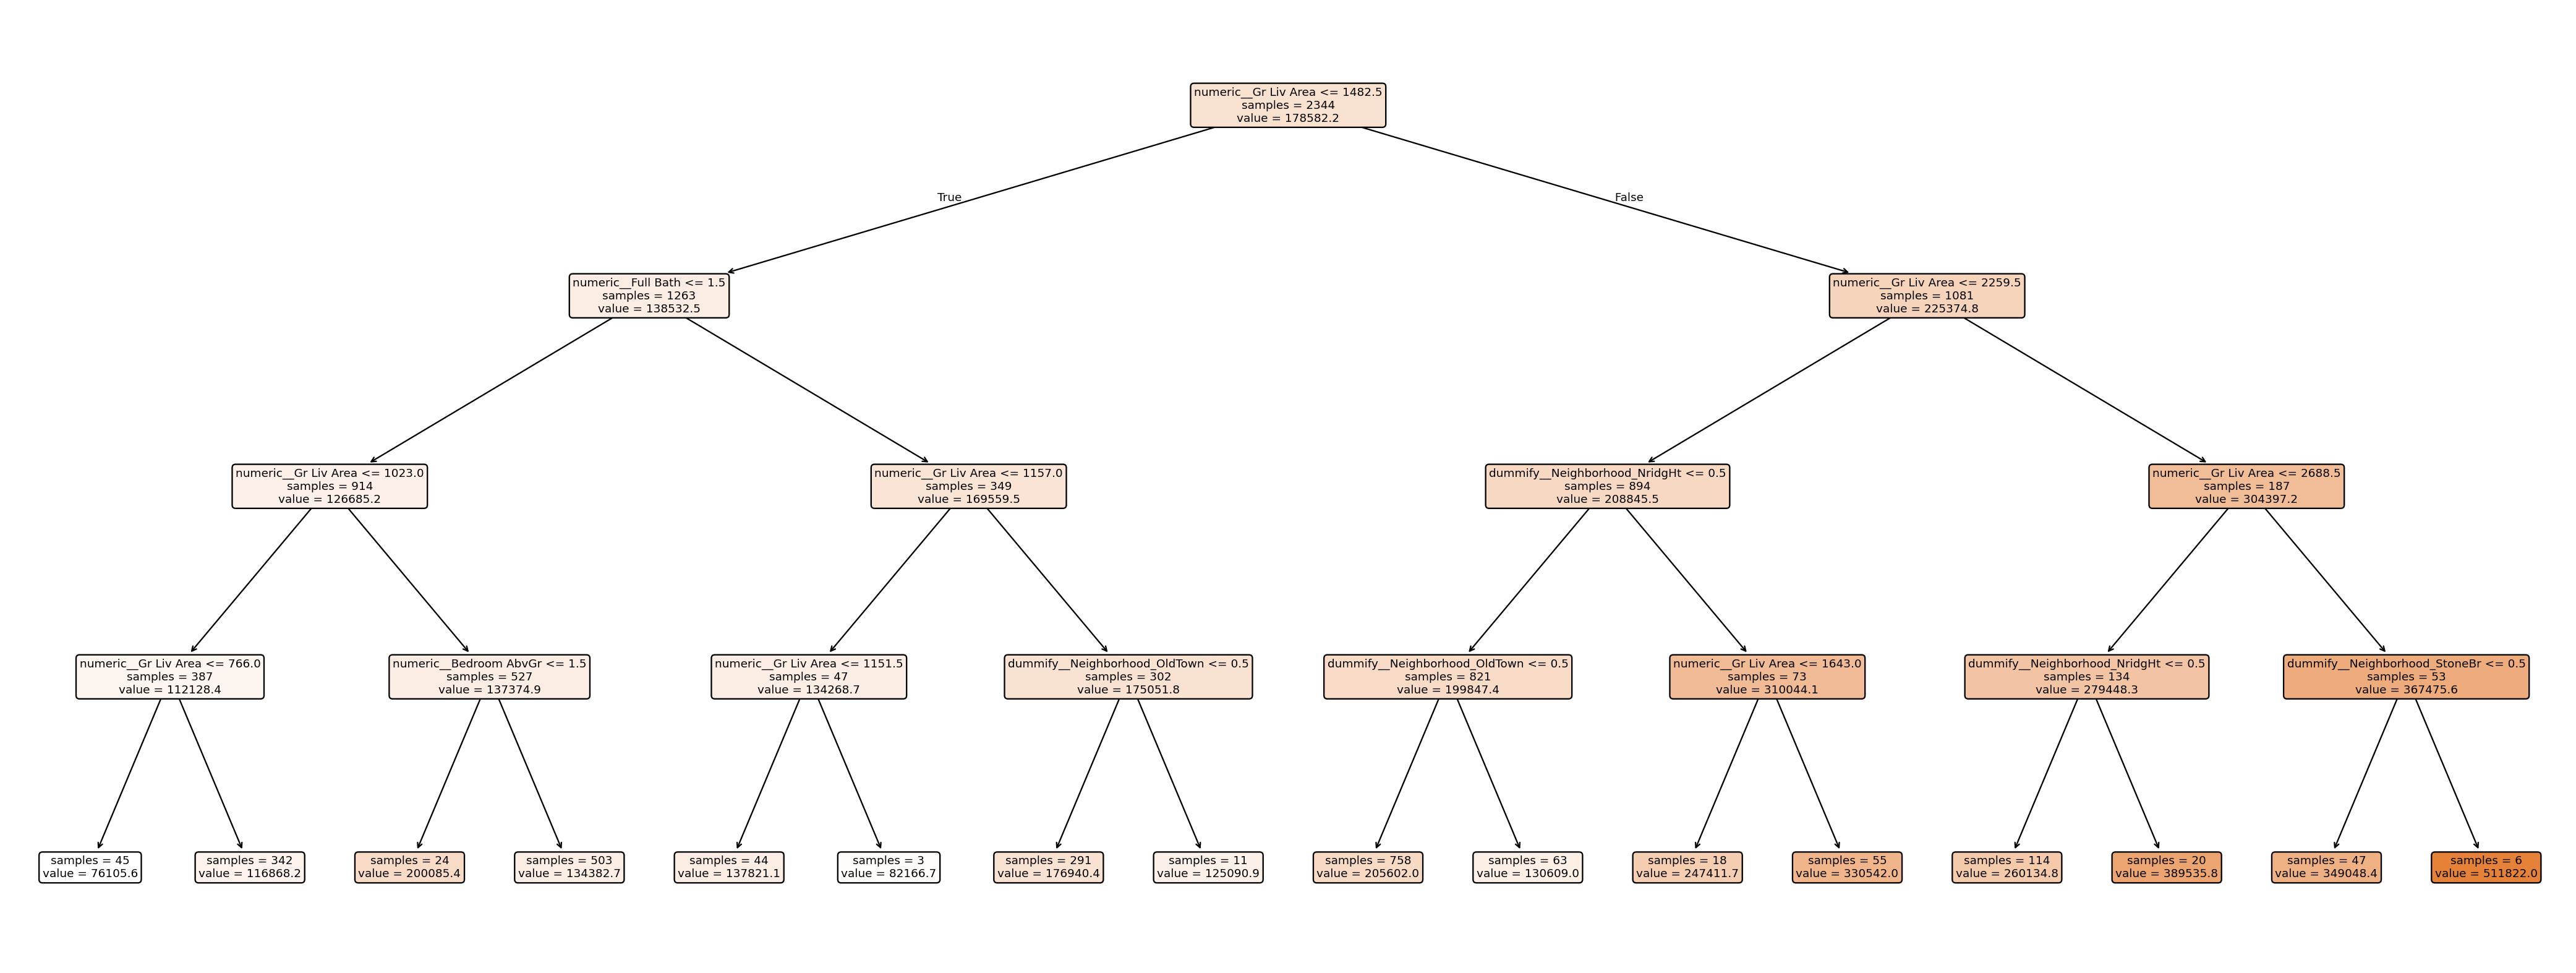

In [20]:
from sklearn.tree import plot_tree

feature_names = (
    tree_model.named_steps["preprocessing"]
    .get_feature_names_out()
)

plt.figure(figsize=(32, 12))

plot_tree(
    tree_model.named_steps["decision_tree"],
    feature_names=feature_names,
    filled=True,
    rounded=True,
    impurity=False,
    precision=1,
    fontsize=8
)

plt.show()

Answer: The tree first splits homes by whether Gr Liv Area is less than or equal to 1482.5 square feet. The smaller-home group is then split by Full Bath at 1.5, while the larger-home group is split again by Gr Liv Area at 2259.5. Later splits also use bedrooms and neighborhood indicators. For example, Neighborhood_NridgHt <= 0.5 separates homes outside NridgHt from homes in that neighborhood. Each leaf predicts the mean SalePrice of the training homes in that leaf, so homes reaching the same leaf receive the same prediction.

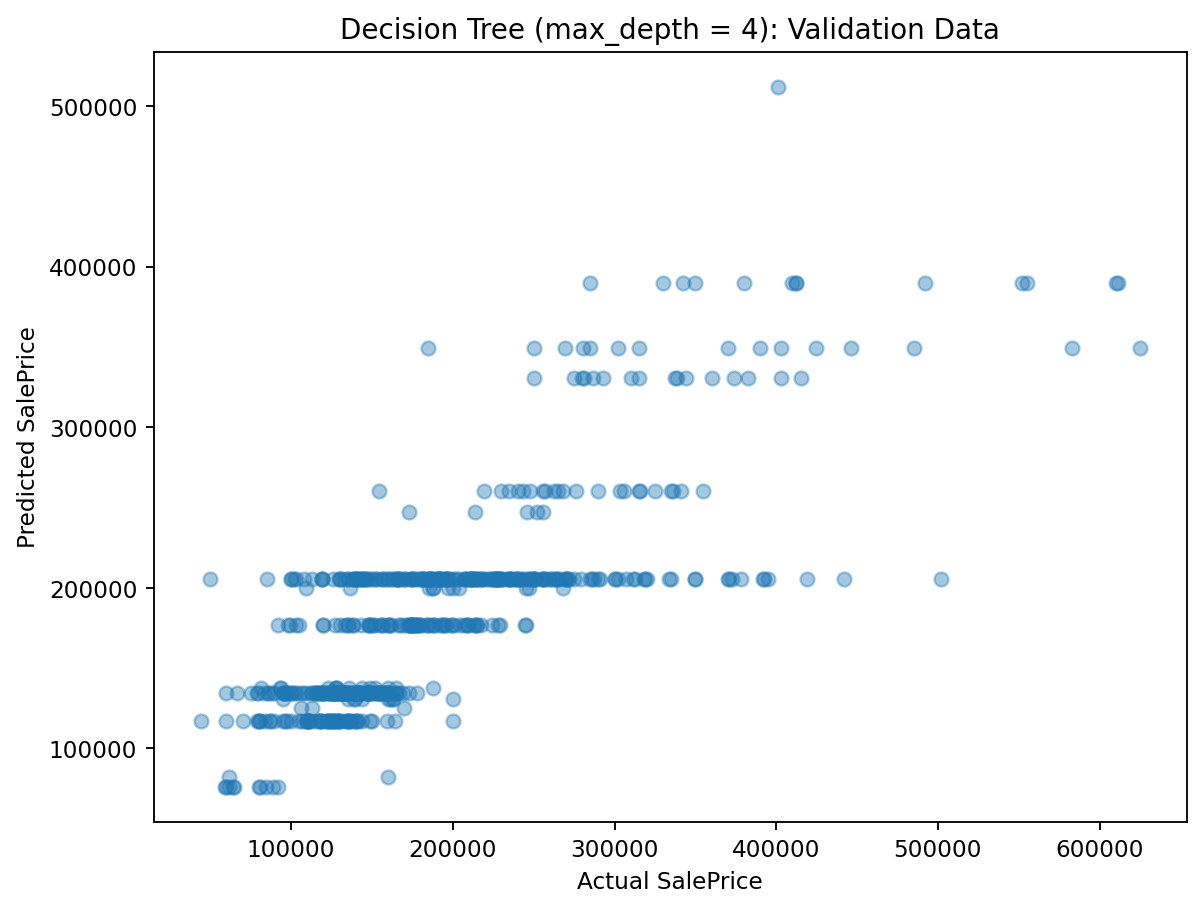

In [21]:
tree_valid_pred = tree_model.predict(X_valid_housing)

plt.figure(figsize=(8, 6))
plt.scatter(y_valid_housing, tree_valid_pred, alpha=0.4)
plt.xlabel("Actual SalePrice")
plt.ylabel("Predicted SalePrice")
plt.title("Decision Tree (max_depth = 4): Validation Data")
plt.show()

14. Repeat the previous part with different values of `max_depth`. What value of seems to be "best"? How are you deciding?

In [22]:
tree_mae_4 = mean_absolute_error(
    y_valid_housing,
    tree_valid_pred
)

print("max_depth:", 4)
print("Validation MAE:", tree_mae_4)

max_depth: 4
Validation MAE: 37204.71664323149


In [23]:
depth = 2

tree_ct_compare = ColumnTransformer([
    ("numeric", "passthrough", numeric_features),
    ("dummify", OneHotEncoder(handle_unknown="ignore"),
     categorical_features)
])

tree_compare_model = Pipeline([
    ("preprocessing", tree_ct_compare),
    ("decision_tree", DecisionTreeRegressor(
        max_depth=depth,
        random_state=42
    ))
])

tree_compare_model.fit(X_train_housing, y_train_housing)

tree_compare_pred = tree_compare_model.predict(X_valid_housing)

tree_compare_mae = mean_absolute_error(
    y_valid_housing,
    tree_compare_pred
)

print("max_depth:", depth)
print("Validation MAE:", tree_compare_mae)

max_depth: 2
Validation MAE: 43405.20153894557


In [24]:
depth = 6

tree_ct_compare = ColumnTransformer([
    ("numeric", "passthrough", numeric_features),
    ("dummify", OneHotEncoder(handle_unknown="ignore"),
     categorical_features)
])

tree_compare_model = Pipeline([
    ("preprocessing", tree_ct_compare),
    ("decision_tree", DecisionTreeRegressor(
        max_depth=depth,
        random_state=42
    ))
])

tree_compare_model.fit(X_train_housing, y_train_housing)

tree_compare_pred = tree_compare_model.predict(X_valid_housing)

tree_compare_mae = mean_absolute_error(
    y_valid_housing,
    tree_compare_pred
)

print("max_depth:", depth)
print("Validation MAE:", tree_compare_mae)

max_depth: 6
Validation MAE: 32074.264404542864


Answer: I compared max_depth values of 2, 4, and 6 using the same training and validation split. Their validation MAEs were 43405.20, 37204.72, and 32074.26 dollars, respectively. A max_depth of 6 performed best among the values tested because it had the lowest validation MAE. Increasing the depth improved validation performance in this comparison, but a deeper tree is not always better because it can overfit the training data.